# Four stocks: adjusted-price histories

Read `Data/BMG9156K1018_10.09.2026_14.59.34.csv` and concatenate the historical ISINs for KONGSBERG GRUPPEN, FRONTLINE, WILH Wilhelmsen B, and TOMRA SYSTEMS.

Only `Date`, `ISIN`, `SecurityId`, `CompanyId`, and `AdjustedPrice` are loaded. `Company` is an added label for joining each history. The ISIN mapping below was checked against the export's company names, including earlier names. Wilhelmsen B is selected by ISIN because the A and B shares share CompanyId 2405.

“Continuous” means one chronologically ordered series of recorded observations per company. Prices are used as supplied, without rescaling, interpolation, or filling missing dates.

All histories are trimmed to 1 January 2005 through Frontline's last recorded date. Each stock keeps its available observations within that common window after the market-closure filter below.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

DATA_FILE = "BMG9156K1018_10.09.2026_14.59.34.csv"
# Locate the data from the notebook directory or the repository root.
root = next(
    directory for directory in [Path.cwd(), *Path.cwd().parents]
    if (directory / "Data" / DATA_FILE).is_file()
)
data_path = root / "Data" / DATA_FILE
columns = ["Date", "ISIN", "SecurityId", "CompanyId", "AdjustedPrice"]

company_isins = {
    "KONGSBERG GRUPPEN": ["NO0003043309", "NO0013536151"],
    "FRONTLINE": ["BMG368191034", "BMG3682E1012", "BMG3682E1921", "CY0200352116"],
    "WILH Wilhelmsen B": ["NO0010576010"],
    "TOMRA SYSTEMS": ["NO0005668905", "NO0012470089"],
}
isin_to_company = {
    isin: company for company, isins in company_isins.items() for isin in isins
}

# Read the large export in chunks, retaining only the selected securities.
parts = []
for chunk in pd.read_csv(
    data_path, sep=";", decimal=",", usecols=columns,
    dtype={"ISIN": "string", "SecurityId": "Int64", "CompanyId": "Int64"},
    chunksize=200_000,
):
    parts.append(chunk.loc[chunk["ISIN"].isin(isin_to_company), columns].copy())

stock_data = pd.concat(parts, ignore_index=True)
stock_data["Date"] = pd.to_datetime(stock_data["Date"], format="%Y-%m-%d")
stock_data["Company"] = stock_data["ISIN"].map(isin_to_company)
stock_data = stock_data.sort_values(["Company", "Date"]).reset_index(drop=True)

# Start all four histories in 2005 and retain the existing common end date.
frontline_dates = stock_data.loc[stock_data["Company"].eq("FRONTLINE"), "Date"]
start_date = pd.Timestamp("2005-01-01")
end_date = frontline_dates.max()
stock_data = stock_data.loc[
    stock_data["Date"].between(start_date, end_date)
].reset_index(drop=True)
# Additional flagged dates confirmed closed in Euronext's 2021–2026 calendars:
# https://www.euronext.com/en/trading/trading-hours-holidays
# Each row lists Maundy Thursday, Ascension Day, and Whit Monday for that year.
other_market_holidays = pd.to_datetime([
    "2021-04-01", "2021-05-13", "2021-05-24",
    "2022-04-14", "2022-05-26", "2022-06-06",
    "2023-04-06", "2023-05-18", "2023-05-29",
    "2024-03-28", "2024-05-09", "2024-05-20",
    "2025-04-17", "2025-05-29", "2025-06-09",
    "2026-04-02", "2026-05-14", "2026-05-25",
])
fixed_date_closure = stock_data["Date"].dt.strftime("%m-%d").isin(
    ["12-24", "12-31", "05-17"]
)
closed = fixed_date_closure | stock_data["Date"].isin(other_market_holidays)
removed_market_dates = pd.DatetimeIndex(
    stock_data.loc[closed, "Date"].unique()
).sort_values()
stock_data = stock_data.loc[~closed].reset_index(drop=True)
del parts, chunk

print(f"Source: {data_path}")
print(f"Loaded {len(stock_data):,} observations across {len(company_isins)} companies.")
print(f"Common period: {start_date:%Y-%m-%d} to {end_date:%Y-%m-%d}")
print(f"Removed {len(removed_market_dates)} distinct market-closure dates before calculating returns.")
display(stock_data.head())

Source: /Users/pasha/Desktop/master/master_thesis/Data/BMG9156K1018_10.09.2026_14.59.34.csv
Loaded 21,403 observations across 4 companies.
Common period: 2005-01-01 to 2026-09-08
Removed 30 distinct market-closure dates before calculating returns.


,Date,ISIN,SecurityId,CompanyId,AdjustedPrice,Company
0,2005-01-03,BMG3682E1921,38027,6117,624.751583,FRONTLINE
1,2005-01-04,BMG3682E1921,38027,6117,635.543837,FRONTLINE
2,2005-01-05,BMG3682E1921,38027,6117,649.933509,FRONTLINE
3,2005-01-06,BMG3682E1921,38027,6117,659.526624,FRONTLINE
4,2005-01-07,BMG3682E1921,38027,6117,667.920599,FRONTLINE


## Inspect the source histories

The table keeps the original security and company identifiers. Kongsberg's replacement ISIN `NO0013536151` has missing `SecurityId` and `CompanyId`; those values remain missing and the ISIN mapping joins its history. Frontline's earliest history has CompanyId 6039, while later records have 6117.

In [2]:
isin_history = (
    stock_data.groupby(["Company", "ISIN", "SecurityId", "CompanyId"], dropna=False)
    .agg(
        start_date=("Date", "min"),
        end_date=("Date", "max"),
        observations=("Date", "size"),
        available_prices=("AdjustedPrice", "count"),
    )
    .reset_index()
    .sort_values(["Company", "start_date"])
)
display(isin_history)

,Company,ISIN,SecurityId,CompanyId,start_date,end_date,observations,available_prices
0,FRONTLINE,BMG3682E1921,38027,6117,2005-01-03,2023-01-12,4531,4531
1,FRONTLINE,CY0200352116,38027,6117,2023-01-13,2026-09-08,914,914
2,KONGSBERG GRUPPEN,NO0003043309,6177,2331,2005-01-03,2025-06-02,5084,5084
3,KONGSBERG GRUPPEN,NO0013536151,<NA>,<NA>,2025-06-03,2026-09-08,319,319
4,TOMRA SYSTEMS,NO0005668905,6282,2392,2005-01-03,2022-05-25,4368,4368
5,TOMRA SYSTEMS,NO0012470089,6282,2392,2022-05-27,2026-09-08,1077,1077
6,WILH Wilhelmsen B,NO0010576010,6311,2405,2005-01-03,2026-09-08,5110,5110


## Concatenate and verify

`stock_data` contains the joined histories with their source identifiers. `adjusted_prices` contains one column per company, indexed by date. Empty cells in that wide table mean the company has no observation on that date.

Check that every company is present, every price is finite and positive, and each company has only one observation per date. The notebook stops on overlapping dates rather than choosing a security or averaging prices.

In [3]:
assert set(stock_data["Company"]) == set(company_isins), "A company is missing."
assert stock_data["Date"].notna().all(), "Missing observation dates."
assert np.isfinite(stock_data["AdjustedPrice"]).all(), "Missing or infinite prices."
assert stock_data["AdjustedPrice"].gt(0).all(), "Nonpositive adjusted prices."
assert not stock_data.duplicated(["Company", "Date"]).any(), (
    "Overlapping histories: inspect duplicate company/date records before joining."
)

adjusted_prices = stock_data.pivot(
    index="Date", columns="Company", values="AdjustedPrice"
).reindex(columns=list(company_isins)).sort_index()
adjusted_prices.columns.name = None

coverage = (
    stock_data.groupby("Company")
    .agg(
        start_date=("Date", "min"),
        end_date=("Date", "max"),
        observations=("Date", "size"),
        historical_isins=("ISIN", "nunique"),
    )
    .reindex(company_isins)
)
print("Verified: four series, unique dates, and finite positive source prices.")
display(coverage)
display(adjusted_prices.tail())

Verified: four series, unique dates, and finite positive source prices.


,start_date,end_date,observations,historical_isins
Company,,,,
KONGSBERG GRUPPEN,2005-01-03,2026-09-08,5403,2
FRONTLINE,2005-01-03,2026-09-08,5445,2
WILH Wilhelmsen B,2005-01-03,2026-09-08,5110,1
TOMRA SYSTEMS,2005-01-03,2026-09-08,5445,2


,KONGSBERG GRUPPEN,FRONTLINE,WILH Wilhelmsen B,TOMRA SYSTEMS
Date,,,,
2026-09-02,311.1,413.8,753.0,106.5
2026-09-03,307.2,423.2,758.0,105.6
2026-09-04,308.4,435.3,773.0,105.9
2026-09-07,298.0,424.9,786.0,97.1
2026-09-08,301.2,427.0,770.0,98.5


In [4]:
# Inspect the price immediately before and after each ISIN change.
previous = stock_data.groupby("Company")[["Date", "ISIN", "AdjustedPrice"]].shift()
changed = previous["ISIN"].notna() & stock_data["ISIN"].ne(previous["ISIN"])
isin_transitions = stock_data.loc[
    changed, ["Company", "Date", "ISIN", "AdjustedPrice"]
].copy()
isin_transitions["previous_date"] = previous.loc[changed, "Date"]
isin_transitions["previous_isin"] = previous.loc[changed, "ISIN"]
isin_transitions["previous_price"] = previous.loc[changed, "AdjustedPrice"]
isin_transitions["price_change_pct"] = 100 * (
    isin_transitions["AdjustedPrice"] / isin_transitions["previous_price"] - 1
)
print("Recorded changes across ISIN boundaries; no extra adjustment is applied.")
display(isin_transitions.reset_index(drop=True))

Recorded changes across ISIN boundaries; no extra adjustment is applied.


,Company,Date,ISIN,AdjustedPrice,previous_date,previous_isin,previous_price,price_change_pct
0,FRONTLINE,2023-01-13,CY0200352116,94.242034,2023-01-12,BMG3682E1921,94.950621,-0.746269
1,KONGSBERG GRUPPEN,2025-06-03,NO0013536151,293.920262,2025-06-02,NO0003043309,286.236852,2.684284
2,TOMRA SYSTEMS,2022-05-27,NO0012470089,177.226119,2022-05-25,NO0005668905,164.171307,7.951945


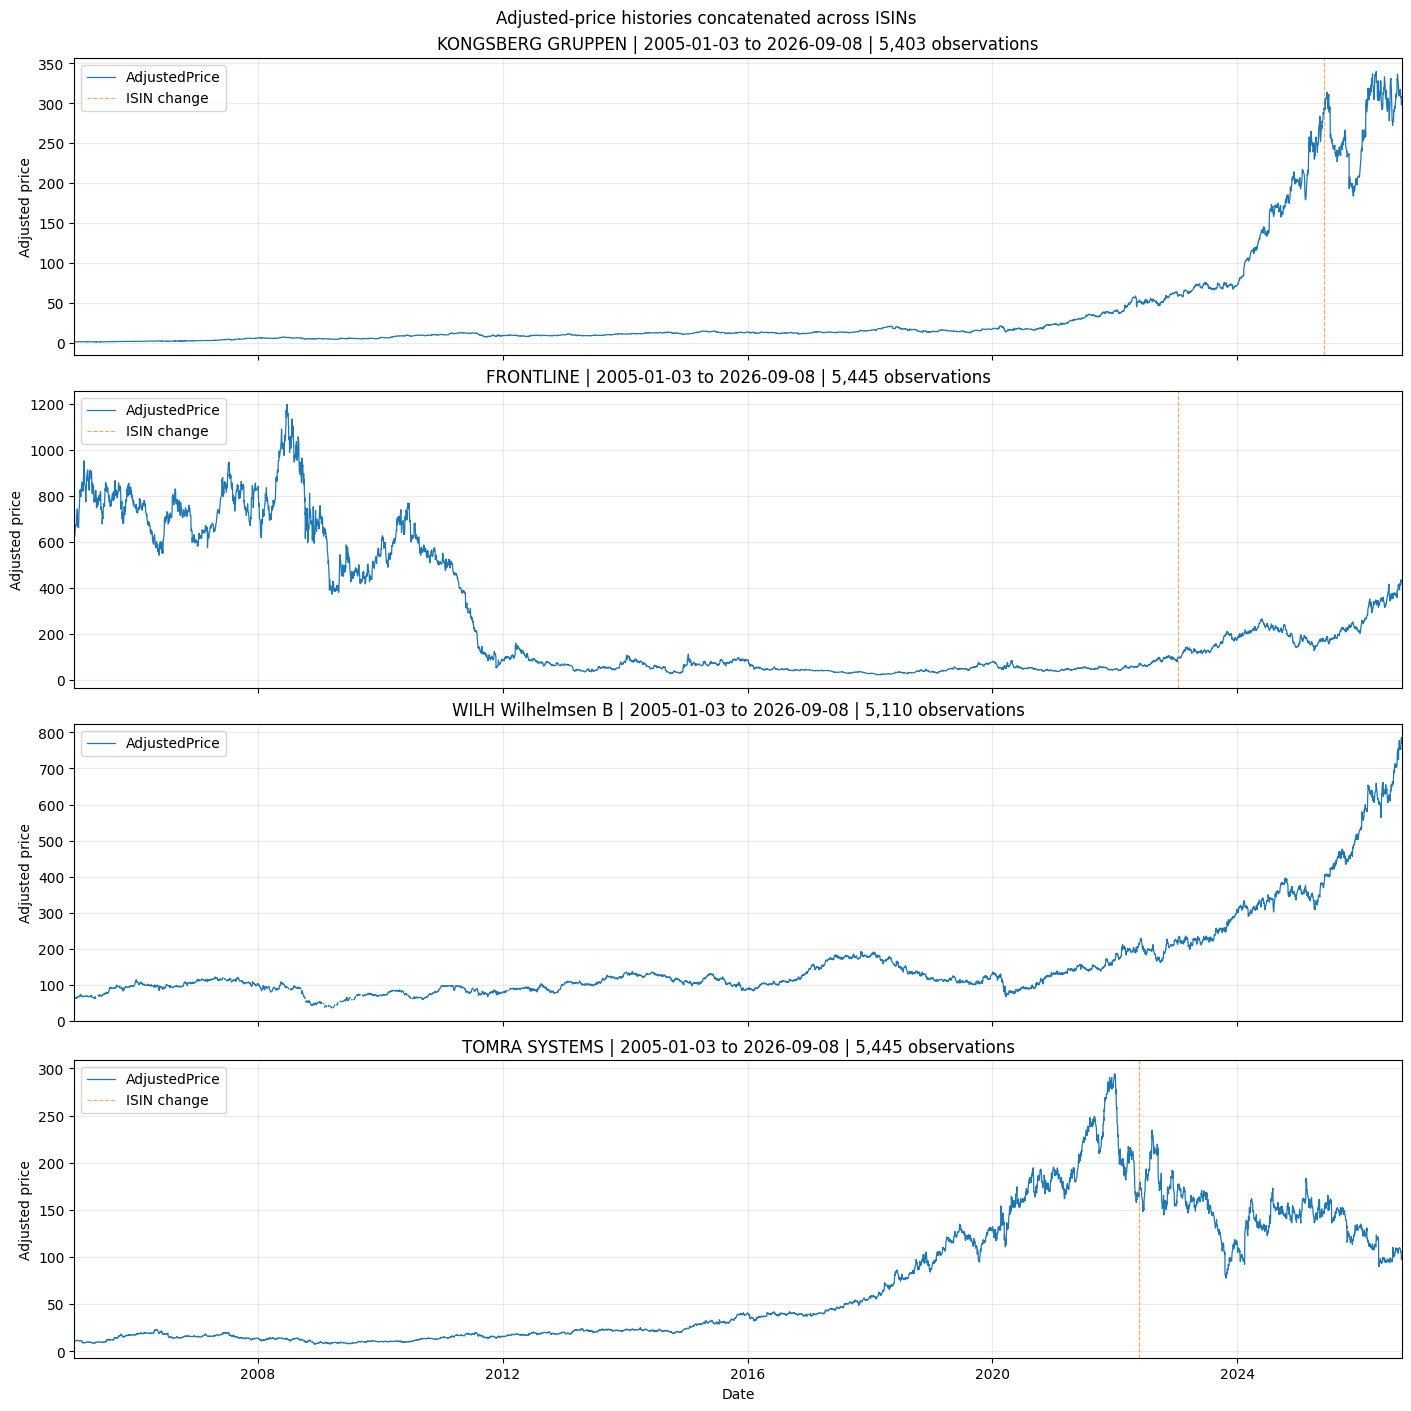

In [5]:
fig, axes = plt.subplots(
    4, 1, figsize=(14, 14), sharex=True, constrained_layout=True
)
for ax, company in zip(axes, company_isins):
    series = adjusted_prices[company]
    ax.plot(series.index, series, linewidth=0.9, label="AdjustedPrice")
    transition_dates = isin_transitions.loc[
        isin_transitions["Company"].eq(company), "Date"
    ]
    for number, date in enumerate(transition_dates):
        ax.axvline(
            date, color="tab:orange", linestyle="--", linewidth=0.8,
            alpha=0.7, label="ISIN change" if number == 0 else None,
        )
    ax.set_title(
        f"{company} | {series.first_valid_index():%Y-%m-%d} to "
        f"{series.last_valid_index():%Y-%m-%d} | {series.count():,} observations"
    )
    ax.set_ylabel("Adjusted price")
    ax.grid(alpha=0.25)
    ax.legend(loc="upper left")

axes[-1].set_xlim(start_date, end_date)
axes[-1].set_xlabel("Date")
fig.suptitle("Adjusted-price histories concatenated across ISINs")
plt.show()
plt.close(fig)

## Daily returns and data diagnostics

Simple returns are $r_t=P_t/P_{t-1}-1$, using `AdjustedPrice`. Returns are stored as fractions: 0.01 means 1%.

The reference calendar is the union of dates recorded for these four stocks within the selected period after removing 24 December, 31 December, and 17 May in every year, plus the 18 other flagged dates confirmed closed in [Euronext's historical Oslo Børs calendars](https://www.euronext.com/en/trading/trading-hours-holidays). These are Maundy Thursday, Ascension Day, and Whit Monday for 2021–2026. The filter removes 30 distinct dates present in this export before returns are calculated. Half trading days remain in the data.

This is an observed calendar with the listed closures removed, not a complete official exchange calendar; dates missing for all four stocks cannot be detected this way. Weekends and removed closure dates are not counted as missing-price gaps.

- **Shared price days:** dates with prices for all four stocks.
- **Shared return days:** dates with valid daily returns for all four stocks.
- **Gap days:** dates in the reference calendar where a stock has no price. A gap run is a consecutive sequence of missing prices on that calendar.
- **Daily returns:** require prices on two consecutive reference dates. No forward filling is applied, and changes spanning missing observations are excluded. The first date has no return and is not itself a gap.
- **Zero returns:** valid returns exactly equal to zero.
- **Extreme returns:** valid simple returns with absolute size at least `EXTREME_RETURN_THRESHOLD` (20% below). These are inspection flags and remain in the data.

Counts of zeros and extremes use each stock's available daily returns; they are not restricted to shared return days.

In [6]:
EXTREME_RETURN_THRESHOLD = 0.20

# Keep the missing prices in place so returns cannot bridge gaps.
daily_returns = adjusted_prices.pct_change(fill_method=None)
assert daily_returns.isna().equals(
    adjusted_prices.isna() | adjusted_prices.shift().isna()
), "Returns must remain missing when either required price is missing."
missing_prices = adjusted_prices.isna()
extreme_mask = daily_returns.abs().ge(EXTREME_RETURN_THRESHOLD)
shared_price_days = int(adjusted_prices.notna().all(axis=1).sum())
shared_daily_returns = daily_returns.dropna(how="any")

return_diagnostics = pd.DataFrame({
    "price_days": adjusted_prices.count(),
    "gap_days": missing_prices.sum(),
    "gap_runs": (missing_prices & ~missing_prices.shift(fill_value=False)).sum(),
    "daily_returns": daily_returns.count(),
    "zero_returns": daily_returns.eq(0).sum(),
    "extreme_returns": extreme_mask.sum(),
    "min_return_pct": daily_returns.min().mul(100),
    "max_return_pct": daily_returns.max().mul(100),
})
return_diagnostics.index.name = "Company"

print(f"Reference calendar: {len(adjusted_prices):,} recorded dates")
print(f"Number of shared price days: {shared_price_days:,}")
print(f"Number of shared daily-return days: {len(shared_daily_returns):,}")
print(f"Extreme-return threshold: absolute simple return >= {EXTREME_RETURN_THRESHOLD:.0%}")
print(return_diagnostics.round(2).to_string())

extreme_return_details = (
    daily_returns.where(extreme_mask).mul(100).stack()
    .rename("Return_pct").rename_axis(["Date", "Company"]).reset_index()
)
print("\nExtreme return observations (percent):")
display(extreme_return_details.round({"Return_pct": 2}))

Reference calendar: 5,445 recorded dates
Number of shared price days: 5,082
Number of shared daily-return days: 4,827
Extreme-return threshold: absolute simple return >= 20%
                   price_days  gap_days  gap_runs  daily_returns  zero_returns  extreme_returns  min_return_pct  max_return_pct
Company                                                                                                                        
KONGSBERG GRUPPEN        5403        42        34           5368           574                0          -18.86           15.90
FRONTLINE                5445         0         0           5444           127               11          -43.50           30.81
WILH Wilhelmsen B        5110       335       244           4865           622                0          -16.13           15.22
TOMRA SYSTEMS            5445         0         0           5444           328                3          -23.78           30.92

Extreme return observations (percent):


,Date,Company,Return_pct
0,2009-05-04,FRONTLINE,25.38
1,2011-11-22,FRONTLINE,-43.50
2,2011-12-06,FRONTLINE,26.49
3,2012-03-16,FRONTLINE,28.98
4,2013-06-17,FRONTLINE,30.81
5,2014-12-12,FRONTLINE,28.10
6,2014-12-15,FRONTLINE,23.87
7,2014-12-18,FRONTLINE,21.79
8,2015-01-06,FRONTLINE,26.04
9,2020-03-30,FRONTLINE,20.00


## Daily-return time series

The four panels use the same date limits as the price plots. Each line shows simple daily returns in percent, with breaks for unavailable returns. Orange points mark the extreme observations reported above. Vertical scales adapt to each stock.

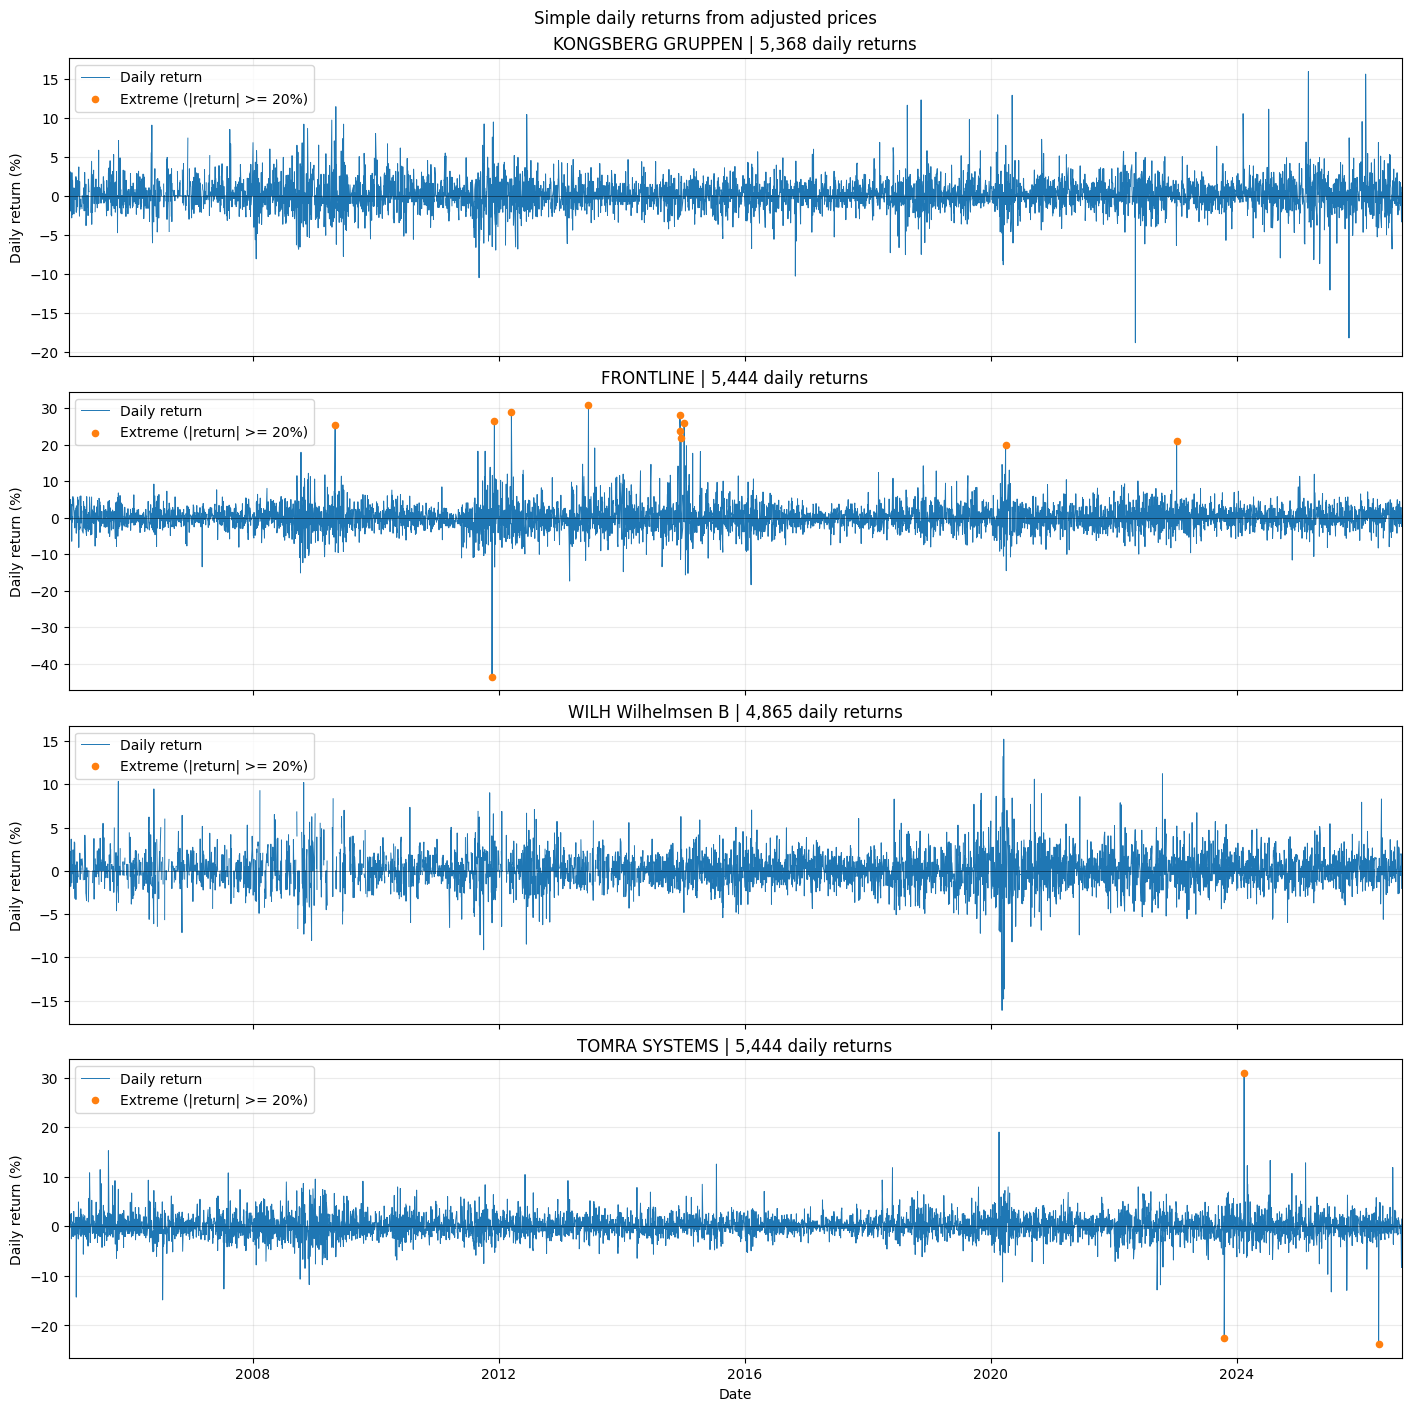

In [7]:
fig, axes = plt.subplots(
    4, 1, figsize=(14, 14), sharex=True, constrained_layout=True
)
for ax, company in zip(axes, company_isins):
    returns_pct = daily_returns[company].mul(100)
    ax.plot(
        returns_pct.index, returns_pct, linewidth=0.7, label="Daily return"
    )
    extreme_dates = extreme_mask[company]
    ax.scatter(
        returns_pct.index[extreme_dates], returns_pct.loc[extreme_dates],
        color="tab:orange", s=20, zorder=3,
        label=f"Extreme (|return| >= {EXTREME_RETURN_THRESHOLD:.0%})",
    )
    ax.axhline(0, color="black", linewidth=0.6, alpha=0.5)
    ax.set_title(f"{company} | {returns_pct.count():,} daily returns")
    ax.set_ylabel("Daily return (%)")
    ax.grid(alpha=0.25)
    ax.legend(loc="upper left")

axes[-1].set_xlim(start_date, end_date)
axes[-1].set_xlabel("Date")
fig.suptitle("Simple daily returns from adjusted prices")
plt.show()
plt.close(fig)

In [8]:
# Split by date without dropping or filling missing returns.
returns_to_save = daily_returns.sort_index()
train_end = int(len(returns_to_save) * 0.70)
validation_end = int(len(returns_to_save) * 0.85)

train_returns = returns_to_save.iloc[:train_end]
validation_returns = returns_to_save.iloc[train_end:validation_end]
test_returns = returns_to_save.iloc[validation_end:]

output_dir = root / "sandbox" / "4stocks_experiment" / "data"
output_dir.mkdir(exist_ok=True)
for filename, split in [
    ("train_returns.csv", train_returns),
    ("validation_returns.csv", validation_returns),
    ("test_returns.csv", test_returns),
]:
    # Returns are fractions; missing returns are written as empty CSV fields.
    split.to_csv(
        output_dir / filename, index_label="Date", date_format="%Y-%m-%d",
        na_rep="", float_format="%.17g",
    )
    print(
        f"{filename}: {len(split):,} rows | "
        f"{split.index.min():%Y-%m-%d} to {split.index.max():%Y-%m-%d}"
    )
print(f"Saved to: {output_dir}")

train_returns.csv: 3,811 rows | 2005-01-03 to 2020-03-05
validation_returns.csv: 817 rows | 2020-03-06 to 2023-06-07
test_returns.csv: 817 rows | 2023-06-08 to 2026-09-08
Saved to: /Users/pasha/Desktop/master/master_thesis/sandbox/4stocks_experiment/data
